# 04 — Ensemble từ checkpoint Phase 3, Colab + Drive

Chỉ dùng validation **28.120 dòng / 375 feature / 587 lớp**, run `baseline-v1-f8a5bfdb7b4c12cd`.
Không fit baseline, calibrator, tune trọng số hoặc mở test. Notebook này chưa có output Colab được xác minh lúc tạo.

## 1. Shared runtime và kiểm checkpoint

Chọn kernel Colab, mount Drive bằng lệnh extension, đồng bộ source mới rồi Restart Kernel.
Setup dưới gọi bootstrap **hiện có**, phase=3 để dùng source/dependency/checkpoint Phase 3;
không cần bootstrap mới. Xem [cách chạy Phase 4](../docs/phase4_ensemble.md).

In [2]:
import runpy, platform
from pathlib import Path
if platform.system() != 'Linux' or not Path('/content').is_dir():
    raise RuntimeError('Chọn Google Colab kernel; /content phải là ổ tạm của runtime.')
DRIVE_ROOT = Path('/content/drive/MyDrive/ML_Projects/disease-prediction-ml')  # Locator sinh từ configs/runtime.json
entry = DRIVE_ROOT / 'src/data/colab_runtime.py'
if not entry.is_file():
    raise FileNotFoundError(f'Không thấy {entry}. Mount Drive và Publish source bằng prepare_colab_source.ps1; không upload script riêng.')
EXPECTED_RUNTIME_PAYLOAD = globals().get('EXPECTED_RUNTIME_PAYLOAD') or input('Paste RUNTIME_PAYLOAD_SHA256 from local Publish: ').strip()
RUNTIME = runpy.run_path(str(entry))['bootstrap_runtime'](DRIVE_ROOT, phase=3, expected_payload_sha256=EXPECTED_RUNTIME_PAYLOAD)
ROOT, runtime_paths = RUNTIME.paths.project_root, RUNTIME.paths

Stage A PASS | Colab Python 3.13.18 | Drive=/content/drive/MyDrive/ML_Projects/disease-prediction-ml | runtime/Drive read-write OK
Stage B PASS | imports=/content/disease-prediction-ml-runtime | source fingerprint=3d2905f3329c3486b435206d9a3e06bdb9a98dc21b7a6f0324880a6a93c583c0


In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from src.models.notebook import ColabTraining
from src.models.ensemble import (
    Phase4, HARD, SOFT, BASELINE, hard_vote,
    diversity_figure, comparison_figure, interpretation, save_phase4, emit_phase4_result,
)

session = ColabTraining.open(RUNTIME)  # Chỉ preflight; không gọi session.train/train_model.
phase = Phase4(session)
verification = phase.verify()
display(verification)
print("Identity/checksum/y_true/row order/mapping/metrics đã kiểm; chỉ train/validation.")

Stage C PASS | manifest=50308d250d874b1b653a71c31f38dece0ec9fbb4dbc9d94f68bc1461e80b8fe9 | 7 train/validation/metadata checksums OK


,Thông tin,Giá trị
0,Runtime,colab
1,Python,3.13.18
2,Scikit-learn,1.6.1
3,RAM khả dụng (GiB),10.627
4,CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
5,GPU phát hiện,[]
6,Drive đọc/ghi,True


Source workspace: /content/disease-prediction-ml-runtime
Source fingerprint: 3d2905f3329c3486b435206d9a3e06bdb9a98dc21b7a6f0324880a6a93c583c0
Dữ liệu / đầu ra Drive: /content/drive/MyDrive/ML_Projects/disease-prediction-ml
Checksum input hợp lệ; chỉ đọc train/validation, không mở CSV test.


,model,integrity,rows,input_features,retained_features,pipeline_bytes,macro_f1,original_predict_seconds
0,logistic_regression,PASS,28120,375,318,1438385,0.787808,2.157469
1,random_forest,PASS,28120,375,318,14420893,0.491997,20.683900
2,linear_svc,PASS,28120,375,318,1463693,0.784222,1.826504
3,knn,PASS,28120,375,318,652535,0.731034,294.224154
4,bernoulli_nb,PASS,28120,375,318,102624,0.599341,5.746997


Identity/checksum/y_true/row order/mapping/metrics đã kiểm; chỉ train/validation.


## 2. Độ khác biệt lỗi — cùng 28.120 hàng

Một heatmap **5×5**: **D** = tỷ lệ hai model dự đoán khác nhau; **J** = tỷ lệ cả hai cùng sai.
Màu theo J. Đường chéo D=0; J là tỷ lệ lỗi của model. Hai nhãn dự đoán khác nhau có thể đều sai.
Bảng rescue bên dưới có hàng A sai, cột B đúng; không phải tỷ lệ điều kiện trên các hàng A sai.

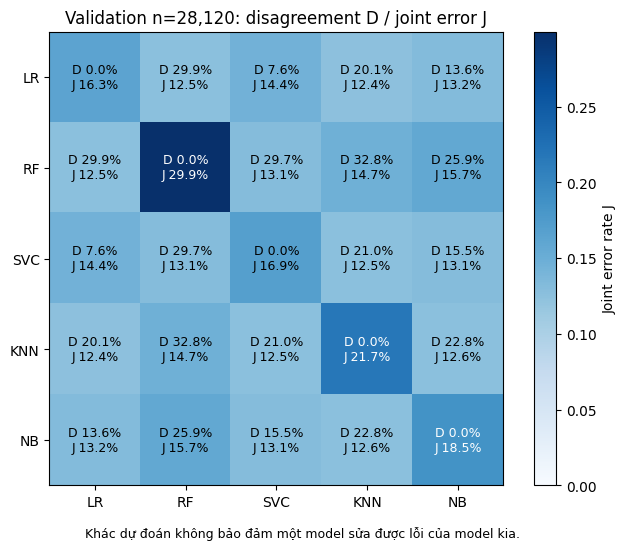

,logistic_regression,random_forest,linear_svc,knn,bernoulli_nb
logistic_regression,0.00000,0.03748,0.01842,0.03862,0.03119
random_forest,0.17404,0.00000,0.16853,0.15263,0.14246
linear_svc,0.02472,0.03826,0.00000,0.04388,0.03869
knn,0.09257,0.07002,0.09154,0.00000,0.09065
bernoulli_nb,0.05341,0.02813,0.05462,0.05893,0.00000


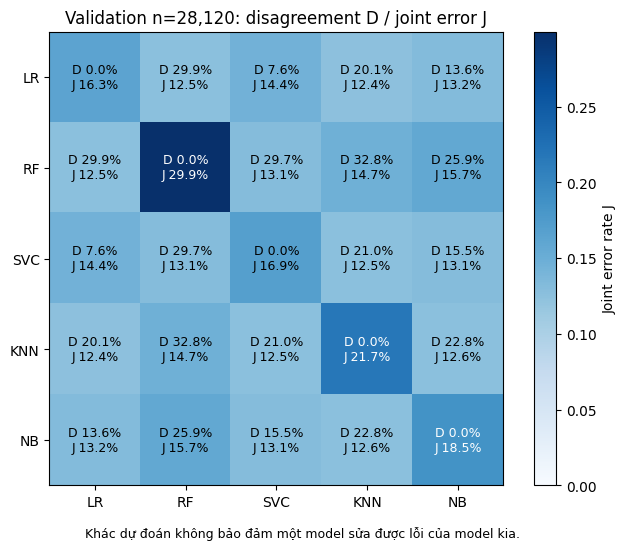

In [3]:
diversity_fig = diversity_figure(phase.diversity)
display(diversity_fig)
display(pd.DataFrame(phase.diversity["a_wrong_b_correct"],
                     index=phase.diversity["names"], columns=phase.diversity["names"]).round(5))

## 3. Hard Voting — ba tổ hợp cố định

LR + SVC + KNN; LR + SVC + NB; LR + SVC + RF. Mỗi model một phiếu.
Nhãn nhiều phiếu nhất thắng; khi ba nhãn khác nhau, ưu tiên dự đoán LR.
Quy tắc tổng quát cho các nhãn đang hòa: LR → SVC → KNN → NB → RF, không chọn theo mã nhãn nhỏ nhất.
Không thử toàn bộ tổ hợp hoặc tối ưu trọng số.

In [4]:
display(pd.DataFrame([{"combination": key, "members": " + ".join(members)} for key, members in HARD.items()]))
hard_results = phase.evaluate_hard()
display(hard_results.round(6))

# Minh họa quá trình vote trên 8 hàng validation thực, không fit model.
members = HARD["hard_lr_svc_knn"]
voted, tie_count = hard_vote(phase.predictions, members, len(phase.classes))
example = {name: [phase.classes[i] for i in phase.predictions[name][:8]] for name in members}
example["hard_vote"] = [phase.classes[i] for i in voted[:8]]
example["y_true"] = [phase.classes[i] for i in phase.y[:8]]
display(pd.DataFrame(example))
print("Số hàng phải phá hòa của tổ hợp này:", tie_count)

,combination,members
0,hard_lr_svc_knn,logistic_regression + linear_svc + knn
1,hard_lr_svc_nb,logistic_regression + linear_svc + bernoulli_nb
2,hard_lr_svc_rf,logistic_regression + linear_svc + random_forest


,combination,mode,status,base_models,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,predicted_classes,classes_f1_zero,tie_rows,delta_macro_f1_vs_lr,pipeline_bytes,original_base_predict_seconds_sum,reason
0,single_logistic_regression,single,completed,1,0.837091,0.827420,0.779189,0.787808,0.836675,560,28,0,0.000000,1438385,2.157469,
1,hard_lr_svc_knn,hard,completed,3,0.836451,0.821900,0.781083,0.787334,0.835979,559,29,1000,-0.000474,3554613,298.208127,
2,hard_lr_svc_nb,hard,completed,3,0.836131,0.827957,0.771870,0.784789,0.835346,558,30,659,-0.003019,3004702,9.730969,
3,hard_lr_svc_rf,hard,completed,3,0.835455,0.825147,0.773429,0.784053,0.834776,558,30,1263,-0.003755,17322971,24.667872,


,logistic_regression,linear_svc,knn,hard_vote,y_true
0,panic disorder,panic disorder,panic disorder,panic disorder,panic disorder
1,panic disorder,panic disorder,anxiety,panic disorder,panic disorder
2,panic disorder,panic disorder,panic disorder,panic disorder,panic disorder
3,anxiety,panic disorder,panic disorder,panic disorder,panic disorder
4,panic disorder,panic disorder,panic disorder,panic disorder,panic disorder
5,panic disorder,panic disorder,panic disorder,panic disorder,panic disorder
6,panic disorder,panic disorder,panic disorder,panic disorder,panic disorder
7,panic disorder,panic disorder,panic disorder,panic disorder,panic disorder


Số hàng phải phá hòa của tổ hợp này: 1000


## 4. Xác suất cho Soft Voting

Chỉ LR/NB/RF/KNN. LinearSVC không tham gia; không fit calibrator, không softmax decision scores,
không tạo one-hot từ hard predictions. Ưu tiên `y_proba` đã lưu trong payload Phase 3 được kiểm checksum,
có class_ids và metadata `probability_method=predict_proba`. Nếu không có, gọi `predict_proba` của checkpoint tin cậy.
Kiểm class order, cùng hàng validation, finite/nonnegative, tổng mỗi hàng ≈1 và argmax khớp hard prediction gốc.

Inference theo batch 64, model load tuần tự. Xác suất nằm trong cache tạm `/content`, không ghi ma trận lớn lên Drive.
KNN có thể mất vài phút. Các warning mới được ghi riêng; không có fitting. Nếu môi trường/source/RAM không hỗ trợ,
ghi lý do và bỏ qua tổ hợp thiếu probability; checksum sai thì dừng. Xác suất hợp lệ về cấu trúc chưa chứng minh calibration.

In [5]:
probability_summary = phase.prepare_probabilities(trusted=True)  # Chỉ checkpoint do dự án của bạn tạo.
display(probability_summary)
print("Limitations:", phase.limitations)

logistic_regression: chưa có persisted probability hợp lệ; chạy predict_proba validation theo batch.
logistic_regression: probability 64/28,120
logistic_regression: probability 28,120/28,120
random_forest: chưa có persisted probability hợp lệ; chạy predict_proba validation theo batch.
random_forest: probability 64/28,120
random_forest: probability 13,376/28,120
random_forest: probability 26,752/28,120
random_forest: probability 28,120/28,120
knn: chưa có persisted probability hợp lệ; chạy predict_proba validation theo batch.
knn: probability 64/28,120
knn: probability 1,536/28,120
knn: probability 3,008/28,120
knn: probability 4,416/28,120
knn: probability 5,824/28,120
knn: probability 7,232/28,120
knn: probability 8,640/28,120
knn: probability 10,048/28,120
knn: probability 11,456/28,120
knn: probability 12,928/28,120
knn: probability 14,400/28,120
knn: probability 15,808/28,120
knn: probability 17,216/28,120
knn: probability 18,688/28,120
knn: probability 20,160/28,120
knn: probabili

,model,available,method,validation_seconds
0,logistic_regression,True,trusted_fitted_pipeline.predict_proba,10.747018
1,random_forest,True,trusted_fitted_pipeline.predict_proba,34.848540
2,knn,True,trusted_fitted_pipeline.predict_proba,300.938051
3,bernoulli_nb,True,trusted_fitted_pipeline.predict_proba,12.703770


Limitations: []


## 5. Soft Voting — hai tổ hợp cố định

LR + NB + RF; LR + KNN + NB. Lấy trung bình xác suất với trọng số đều rồi chọn nhãn có giá trị cao nhất.
Nếu bằng nhau chính xác: so xác suất LR giữa các nhãn đang hòa, rồi theo tên nhãn tiếng Anh Unicode.
Không tối ưu trọng số theo validation. Tổ hợp chưa đủ dữ liệu có metric trống, không thay bằng điểm giả.

In [6]:
display(pd.DataFrame([{"combination": key, "members": " + ".join(members), "weights": "uniform"} for key, members in SOFT.items()]))
soft_results = phase.evaluate_soft()
display(soft_results.round(6))

,combination,members,weights
0,soft_lr_nb_rf,logistic_regression + bernoulli_nb + random_fo...,uniform
1,soft_lr_knn_nb,logistic_regression + knn + bernoulli_nb,uniform


,combination,mode,status,base_models,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,predicted_classes,classes_f1_zero,tie_rows,delta_macro_f1_vs_lr,pipeline_bytes,original_base_predict_seconds_sum,reason
0,single_logistic_regression,single,completed,1,0.837091,0.827420,0.779189,0.787808,0.836675,560,28,0,0.000000,1438385,2.157469,
1,hard_lr_svc_knn,hard,completed,3,0.836451,0.821900,0.781083,0.787334,0.835979,559,29,1000,-0.000474,3554613,298.208127,
2,hard_lr_svc_nb,hard,completed,3,0.836131,0.827957,0.771870,0.784789,0.835346,558,30,659,-0.003019,3004702,9.730969,
3,hard_lr_svc_rf,hard,completed,3,0.835455,0.825147,0.773429,0.784053,0.834776,558,30,1263,-0.003755,17322971,24.667872,
4,soft_lr_nb_rf,soft,completed,3,0.825427,0.819365,0.685326,0.724694,0.821102,532,56,0,-0.063114,15961902,28.588366,
5,soft_lr_knn_nb,soft,completed,3,0.826991,0.831142,0.741390,0.763243,0.827000,548,39,0,-0.024566,2193544,302.128620,


## 6. So sánh với Logistic Regression

Macro F1 là metric chính, zero_division=0. Baseline phải tái lập **0.78780814** trong tolerance làm tròn8 chữ số.
Ứng viên đứng đầu được chọn theo Macro F1, hòa chính xác thì ít model hơn rồi ID ổn định.
Chênh lệch nhỏ không đồng nghĩa có ý nghĩa thống kê; validation đã dùng nhiều lần để so sánh.

,combination,mode,status,base_models,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,predicted_classes,classes_f1_zero,tie_rows,delta_macro_f1_vs_lr,pipeline_bytes,original_base_predict_seconds_sum,reason
0,single_logistic_regression,single,completed,1,0.837091,0.827420,0.779189,0.787808,0.836675,560,28,0,0.000000,1438385,2.157469,
1,hard_lr_svc_knn,hard,completed,3,0.836451,0.821900,0.781083,0.787334,0.835979,559,29,1000,-0.000474,3554613,298.208127,
2,hard_lr_svc_nb,hard,completed,3,0.836131,0.827957,0.771870,0.784789,0.835346,558,30,659,-0.003019,3004702,9.730969,
3,hard_lr_svc_rf,hard,completed,3,0.835455,0.825147,0.773429,0.784053,0.834776,558,30,1263,-0.003755,17322971,24.667872,
4,soft_lr_nb_rf,soft,completed,3,0.825427,0.819365,0.685326,0.724694,0.821102,532,56,0,-0.063114,15961902,28.588366,
5,soft_lr_knn_nb,soft,completed,3,0.826991,0.831142,0.741390,0.763243,0.827000,548,39,0,-0.024566,2193544,302.128620,


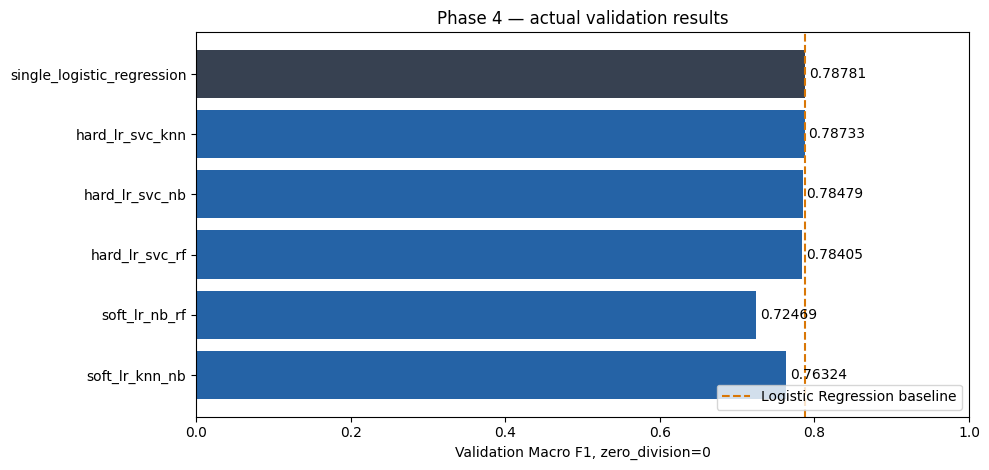

LR/SVC: disagreement=7.6387%; joint error=14.4488%; LR sai, SVC đúng=1.8421%; SVC sai, LR đúng=2.4716%.
hard_lr_svc_knn: sửa 152 hàng LR sai, làm sai 170 hàng LR đúng. hard_lr_svc_nb: sửa 160 hàng LR sai, làm sai 187 hàng LR đúng. hard_lr_svc_rf: sửa 153 hàng LR sai, làm sai 199 hàng LR đúng.
Ứng viên theo validation: single_logistic_regression, Macro F1=0.78780814; delta so LR=+0.00000000. Chưa có ensemble vượt LR trên split này. Chênh lệch không chứng minh ý nghĩa thống kê. Chỉ thử 3 hard/2 soft đã định, không tìm trọng số. Xác suất được kiểm đúng cấu trúc, chưa chứng minh calibration; đây là giới hạn của soft voting. Ba vote với ưu tiên LR khi hòa không cứu được hàng cả LR/SVC cùng sai, ngay cả khi model thứ ba đúng; model thứ ba chỉ đổi quyết định khi tạo đa số hoặc phá tình huống LR/SVC bất đồng. Chi phí prediction cộng của baseline chỉ là tham chiếu, không phải benchmark ensemble hoặc latency chatbot. KNN chậm trên toàn validation; số byte checkpoint nén không phải peak RAM. Support lớp nhỏ và việc dùng lại validation để lựa chọn hạn chế kết luận tổng quát hóa. Không mở test.

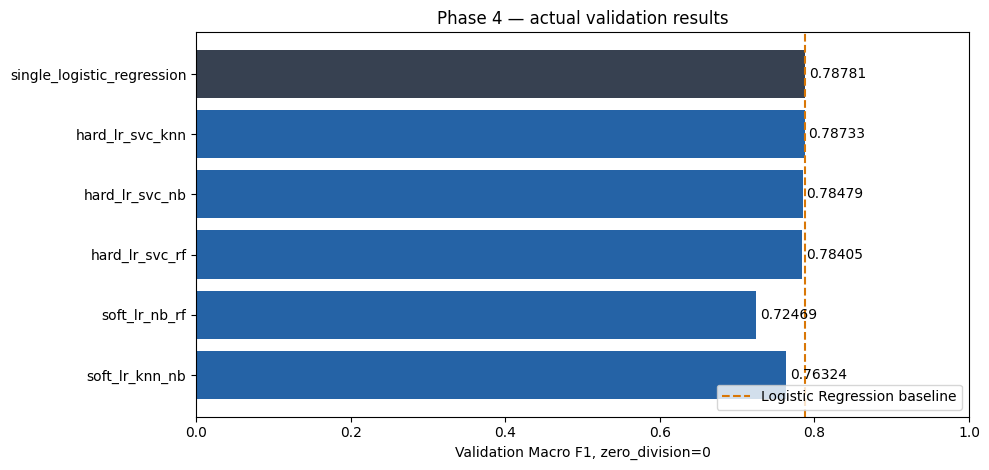

In [7]:
display(phase.table().round(6))
comparison_fig = comparison_figure(phase)
display(comparison_fig)
display(Markdown(interpretation(phase)))

## 7. Inference một vector và trade-off triển khai

Wrapper tham chiếu pipeline Phase 3, không sao chép hoặc fit lại model; input vẫn là375 feature trước variance.
Kiểm một hàng validation375 feature cho kết quả giống bước evaluate, không thực hiện benchmark latency.
Kích thước dưới là file nén, không phải peak RAM. Tổng thời gian baseline là tham chiếu chi phí tương đối,
không phải thời gian ensemble đo mới hoặc latency một người dùng. KNN là điểm cần cân nhắc nếu mức cải thiện nhỏ.

In [8]:
display(pd.DataFrame([phase.single_input_check(trusted=True)]))
display(phase.table()[["combination", "status", "base_models", "pipeline_bytes", "original_base_predict_seconds_sum", "delta_macro_f1_vs_lr"]].round(6))

,status,input_features,matches_validation_row_0
0,PASS,375,True


,combination,status,base_models,pipeline_bytes,original_base_predict_seconds_sum,delta_macro_f1_vs_lr
0,single_logistic_regression,completed,1,1438385,2.157469,0.000000
1,hard_lr_svc_knn,completed,3,3554613,298.208127,-0.000474
2,hard_lr_svc_nb,completed,3,3004702,9.730969,-0.003019
3,hard_lr_svc_rf,completed,3,17322971,24.667872,-0.003755
4,soft_lr_nb_rf,completed,3,15961902,28.588366,-0.063114
5,soft_lr_knn_nb,completed,3,2193544,302.128620,-0.024566


## 8. Lưu kết quả validation về Drive

Một run mới trong reports/runs và artifacts/metadata/runs, định nghĩa trong artifacts/models/phase4.
Lưu bảng, đúng hai hình, predictions ensemble, combo definitions và manifest/checksum. Không ghi đè Phase2/3.
Định nghĩa gồm cả baseline nếu LR vẫn là lựa chọn tốt nhất. Chỉ ghi đề xuất; chưa mở test và chưa chọn model cuối thay người dùng.

In [9]:
phase4_result = save_phase4(phase, diversity_fig, comparison_fig)
print("Manifest Drive:", runtime_paths.storage_root / phase4_result["manifest_relative"])
print("Candidate:", phase4_result["candidate"])
print("Report:", runtime_paths.storage_root / "reports/runs" / phase4_result["run_id"] / "phase4_validation.md")
emit_phase4_result(phase4_result)  # Copy Cell Output hai dòng PHASE4_* để cập nhật log/audit.
phase.close()  # Dọn cache probability tạm; kết quả quan trọng đã lưu Drive.
print("Dừng Phase 4 validation. Chưa evaluate test hoặc triển khai chatbot.")

Manifest Drive: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/artifacts/metadata/runs/phase4-20261028T091711786379Z-c1c66643/phase4_manifest.json
Candidate: {'id': 'single_logistic_regression', 'mode': 'single', 'members': ['logistic_regression'], 'status': 'completed', 'tie_rows': 0, 'accuracy': 0.8370910384068279, 'macro_precision': 0.8274197939731976, 'macro_recall': 0.7791885208694249, 'macro_f1': 0.7878081402467481, 'weighted_f1': 0.836675385063782, 'predicted_classes': 560, 'classes_f1_zero': 28}
Report: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/reports/runs/phase4-20261028T091711786379Z-c1c66643/phase4_validation.md
PHASE4_SHA256=42cf30dc39547656c572cf5ca4bb6a0eae3a6d31f0a923e6518e8618e835dd44
PHASE4_GZIP_BASE64=H4sIAAAAAAAC/+2cW4tk13XHv8qhwBCTo5p9v4zQg6OQl9gmSHYSIoviXLtLU13VrqqeSVvoyQ8hBBNEyEPwQ6SIkMhEoMSBkGmCH9roe/Q3yW+dqr5N10TjixAOZ5itnjq1zr6s3957rf856v3+pK423exk1XaLzayfb7ddO3msyklTLdt5W227yeP3J1XTnK2r5pxvpslGlbWyyamQTMyYLqrNpuNuPftRt15NHptUTuZUM9nMl

## 9. Tuned Ensemble Evaluation — tách riêng kết quả baseline

Chỉ bật sau khi Section 5 notebook 03 đã hoàn tất và lưu manifest trên Drive.
Không cần chạy lại/sinh lại kết quả baseline ở trên: chạy setup và cell mở session/verify,
rồi tới section này. Nếu thiếu tuned checkpoint hoàn tất thì **SKIPPED**; checksum sai thì dừng rõ ràng.
Không fit model/calibrator. Tái sử dụng 3 tổ hợp Hard Voting, 2 Soft Voting,
quy tắc phá hòa và kiểm probability/class/row order hiện có. Mỗi checkpoint nạp tuần tự;
probability theo batch, cache tạm runtime. KNN có thể chậm.

So sánh baseline LR, 5 model selected và 5 ensemble tuned. Macro F1 chính;
hòa chính xác xét số pipeline, có KNN, kích thước file và ID ổn định làm proxy chi phí.
Các proxy không phải latency; thời gian predict từ những phiên khác nhau chỉ là tham chiếu.
Kết quả mới nằm trong run `tuned-ensemble-*`, không ghi đè Phase 3/4 hoặc tự đổi model ứng dụng.


In [3]:
RUN_TUNED_ENSEMBLE = False  # Notebook 04 chỉ evaluate; không fit model.
TUNING_EXPERIMENT_ID = "tuning-v1-9c4dd013abbba14a"  # Có nhiều run: điền experiment_id đã in ở Section 5 notebook 03.


In [4]:
if RUN_TUNED_ENSEMBLE:
    from src.models.tuned_ensemble import evaluate_tuned_ensemble
    tuned_ensemble_result = evaluate_tuned_ensemble(
        session, enabled=True, experiment=TUNING_EXPERIMENT_ID, trusted=True)
    if tuned_ensemble_result is not None:
        display(tuned_ensemble_result["verification"])
        display(tuned_ensemble_result["probabilities"])
        display(tuned_ensemble_result["comparison"].round(6))
        print("Đề xuất validation:", tuned_ensemble_result["recommendation"])
        print("Manifest riêng trên Drive:", tuned_ensemble_result["manifest"])
        print("Không tự thay LR mặc định; chưa mở/evaluate locked test.")
else:
    print("SKIPPED: RUN_TUNED_ENSEMBLE=False; không load/predict tuned models.")


logistic_regression: chưa có persisted probability hợp lệ; chạy predict_proba validation theo batch.
logistic_regression: probability 64/28,120
logistic_regression: probability 28,120/28,120
random_forest: chưa có persisted probability hợp lệ; chạy predict_proba validation theo batch.
random_forest: probability 64/28,120
random_forest: probability 12,992/28,120
random_forest: probability 26,048/28,120
random_forest: probability 28,120/28,120
knn: chưa có persisted probability hợp lệ; chạy predict_proba validation theo batch.
knn: probability 64/28,120
knn: probability 1,536/28,120
knn: probability 3,008/28,120
knn: probability 4,416/28,120
knn: probability 5,824/28,120
knn: probability 7,232/28,120
knn: probability 8,640/28,120
knn: probability 10,048/28,120
knn: probability 11,456/28,120
knn: probability 12,928/28,120
knn: probability 14,400/28,120
knn: probability 15,808/28,120
knn: probability 17,216/28,120
knn: probability 18,688/28,120
knn: probability 20,160/28,120
knn: probabili

,model,checkpoint,schema,classes,validation_alignment,macro_f1
0,logistic_regression,PASS,PASS,587,PASS,0.793154
1,random_forest,PASS,PASS,587,PASS,0.510908
2,linear_svc,PASS,PASS,587,PASS,0.786368
3,knn,PASS,PASS,587,PASS,0.745679
4,bernoulli_nb,PASS,PASS,587,PASS,0.672138


,model,available,method,validation_seconds
0,logistic_regression,True,trusted_fitted_pipeline.predict_proba,8.542713
1,random_forest,True,trusted_fitted_pipeline.predict_proba,36.552896
2,knn,True,trusted_fitted_pipeline.predict_proba,301.204632
3,bernoulli_nb,True,trusted_fitted_pipeline.predict_proba,12.871167


,combination,mode,status,base_models,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,predicted_classes,classes_f1_zero,tie_rows,delta_macro_f1_vs_lr,pipeline_bytes,original_base_predict_seconds_sum,reason,source
0,baseline_logistic_regression,single,completed,1,0.837091,0.827420,0.779189,0.787808,0.836675,560,28,0,0.000000,1438385,2.157469,,verified_baseline
1,single_logistic_regression,single,completed,1,0.837660,0.823867,0.792485,0.793154,0.838440,566,23,0,0.005346,1438563,2.115221,,tuned
2,single_random_forest,single,completed,1,0.742070,0.661775,0.467541,0.510908,0.729883,434,153,0,-0.276900,17388724,20.876340,,tuned
3,single_linear_svc,single,completed,1,0.831117,0.811547,0.788224,0.786368,0.830651,566,23,0,-0.001441,1463321,1.851988,,tuned
4,single_knn,single,completed,1,0.790327,0.792839,0.745752,0.745679,0.793297,562,30,0,-0.042129,652535,296.826149,,tuned
5,single_bernoulli_nb,single,completed,1,0.827276,0.739231,0.646995,0.672138,0.822794,489,99,0,-0.115670,102840,3.761508,,tuned
6,hard_lr_svc_knn,hard,completed,3,0.836913,0.822713,0.798134,0.796517,0.837682,567,21,963,0.008709,3554419,300.793358,,tuned
7,hard_lr_svc_nb,hard,completed,3,0.837091,0.823444,0.782447,0.787256,0.837552,564,25,679,-0.000553,3004724,7.728717,,tuned
8,hard_lr_svc_rf,hard,completed,3,0.835740,0.822678,0.783369,0.787693,0.836270,564,25,1245,-0.000115,20290608,24.843549,,tuned
9,soft_lr_nb_rf,soft,completed,3,0.832681,0.833965,0.735431,0.764871,0.830845,548,41,0,-0.022938,18930127,26.753069,,tuned


Đề xuất validation: {'candidate': 'hard_lr_svc_knn', 'source': 'tuned', 'macro_f1': 0.7965170720239344, 'policy': 'validation Macro F1; exact tie -> fewer pipelines -> no KNN -> fewer compressed bytes -> stable ID', 'cost_limitation': 'Resource proxies, not latency. Saved prediction-time sums can come from different runtime sessions; no SLA.', 'application_model_changed': False, 'locked_test_evaluated': False}
Manifest riêng trên Drive: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/artifacts/metadata/runs/tuned-ensemble-20261029T041701354242Z-6c84dbfe/tuned_ensemble_manifest.json
Không tự thay LR mặc định; chưa mở/evaluate locked test.
